
# Oasis Infobyte Internship — Task 1
## Iris Flower Classification

### 1. Problem Identification

**Problem Statement**

The objective of this project is to develop a machine learning classification system that predicts the species of an Iris flower based on its physical measurements.

**Business / Project Objective**

Build a reliable, reproducible, and reusable classification model that can identify one of three Iris species:
- Iris setosa
- Iris versicolor
- Iris virginica

**Input Features**
- Sepal length (cm)
- Sepal width (cm)
- Petal length (cm)
- Petal width (cm)

**Target Variable**

Species of the Iris flower (three classes).

**Machine Learning Task**

Supervised learning — multiclass classification.

**Success Criteria**
- Perform comprehensive exploratory data analysis.
- Build preprocessing and classification pipelines.
- Train and compare multiple classification algorithms.
- Evaluate models using accuracy, precision, recall, F1-score, and confusion matrices.
- Select a suitable model based on validation results and final test performance.
- Save the complete trained pipeline for future application integration.

**Technology Stack**

Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn, joblib, and Google Colab.


In [1]:

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import load_iris

# Data splitting and preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Model persistence
import joblib

# Reproducibility
RANDOM_STATE = 42

# Visualization defaults
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)

print("Libraries imported successfully.")


Libraries imported successfully.


Data collection

In [2]:

# ============================================================
# 2. LOAD THE IRIS DATASET
# ============================================================

# Load the dataset as a scikit-learn Bunch object
iris = load_iris()

# Create a DataFrame containing the input features
X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Create a target Series containing the numerical class labels
y = pd.Series(
    iris.target,
    name="species"
)

# Create a human-readable mapping for species names
target_names = iris.target_names

# Combine features and target into one DataFrame for exploration
df = X.copy()

df["species"] = y.map(
    {index: name for index, name in enumerate(target_names)}
)

print("Dataset loaded successfully.")
print(f"Number of samples: {df.shape[0]}")
print(f"Number of input features: {X.shape[1]}")
print(f"Number of target classes: {len(target_names)}")


Dataset loaded successfully.
Number of samples: 150
Number of input features: 4
Number of target classes: 3


In [3]:

# ============================================================
# 3. INITIAL DATASET INSPECTION
# ============================================================

print("First five observations:")
display(df.head())

print("\nDataset dimensions:")
print(df.shape)

print("\nFeature names:")
print(X.columns.tolist())

print("\nTarget classes:")
print(target_names.tolist())

print("\nData types:")
print(df.dtypes)


First five observations:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Dataset dimensions:
(150, 5)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target classes:
['setosa', 'versicolor', 'virginica']

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object


Exploratory Data Analysis (EDA)


## 4. Exploratory Data Analysis (EDA)

### 4.1 Data Quality and Structural Validation

Before analyzing distributions or training models, we will inspect the dataset structure, data types, missing values, duplicate observations, and target validity.

This step helps identify data quality issues before modeling.


In [4]:

# ============================================================
# 4.1 DATA QUALITY AND STRUCTURAL VALIDATION
# ============================================================

print("=" * 65)
print("DATASET INFORMATION")
print("=" * 65)

df.info()

print("\n" + "=" * 65)
print("MISSING VALUES")
print("=" * 65)

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": df.isnull().mean() * 100
})

display(missing_summary)

print("\n" + "=" * 65)
print("DUPLICATE OBSERVATIONS")
print("=" * 65)

duplicate_count = df.duplicated().sum()

print(f"Exact duplicate rows: {duplicate_count}")
print(f"Duplicate percentage: {duplicate_count / len(df) * 100:.2f}%")

print("\n" + "=" * 65)
print("TARGET VALIDATION")
print("=" * 65)

print("Unique species:", sorted(df["species"].unique()))
print("Number of species:", df["species"].nunique())
print("Unexpected target values:", df["species"].isna().sum())

print("\n" + "=" * 65)
print("NUMERICAL FEATURE VALIDATION")
print("=" * 65)

print("All feature values finite:",
      np.isfinite(X.to_numpy()).all())

print("\nFeature values below zero:")
display((X < 0).sum().rename("Count").to_frame())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

MISSING VALUES


,Missing Count,Missing Percentage (%)
sepal length (cm),0,0.0
sepal width (cm),0,0.0
petal length (cm),0,0.0
petal width (cm),0,0.0
species,0,0.0



DUPLICATE OBSERVATIONS
Exact duplicate rows: 1
Duplicate percentage: 0.67%

TARGET VALIDATION
Unique species: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Number of species: 3
Unexpected target values: 0

NUMERICAL FEATURE VALIDATION
All feature values finite: True

Feature values below zero:


,Count
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0


Descriptive statistics


### 4.2 Descriptive Statistical Analysis

We will calculate summary statistics for each numerical feature, both across the complete dataset and separately for each species.

This helps us understand central tendency, variability, measurement ranges, and differences between classes.


In [5]:

# ============================================================
# 4.2 DESCRIPTIVE STATISTICS
# ============================================================

print("Overall Feature Statistics")
display(X.describe().T)

print("\nFeature Statistics by Species")

species_statistics = df.groupby("species")[X.columns.tolist()].agg(
    ["mean", "std", "min", "median", "max"]
)

display(species_statistics.round(3))


Overall Feature Statistics


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057,0.436,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758,1.765,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199,0.762,0.1,0.3,1.30,1.8,2.5



Feature Statistics by Species


sepal length (cm)                         sepal width (cm)         \
                        mean    std  min median  max             mean    std   
species                                                                        
setosa                 5.006  0.352  4.3    5.0  5.8            3.428  0.379   
versicolor             5.936  0.516  4.9    5.9  7.0            2.770  0.314   
virginica              6.588  0.636  4.9    6.5  7.9            2.974  0.322   

                            petal length (cm)                          \
            min median  max              mean    std  min median  max   
species                                                                 
setosa      2.3    3.4  4.4             1.462  0.174  1.0   1.50  1.9   
versicolor  2.0    2.8  3.4             4.260  0.470  3.0   4.35  5.1   
virginica   2.2    3.0  3.8             5.552  0.552  4.5   5.55  6.9   

           petal width (cm)                          
                       mean    std  min median  max  
species                                              
setosa                0.246  0.105  0.1    0.2  0.6  
versicolor            1.326  0.198  1.0    1.3  1.8  
virginica             2.026  0.275  1.4    2.0  2.5

Target class distribution

Species Distribution


,Sample Count,Percentage (%)
species,,
setosa,50,33.33
versicolor,50,33.33
virginica,50,33.33


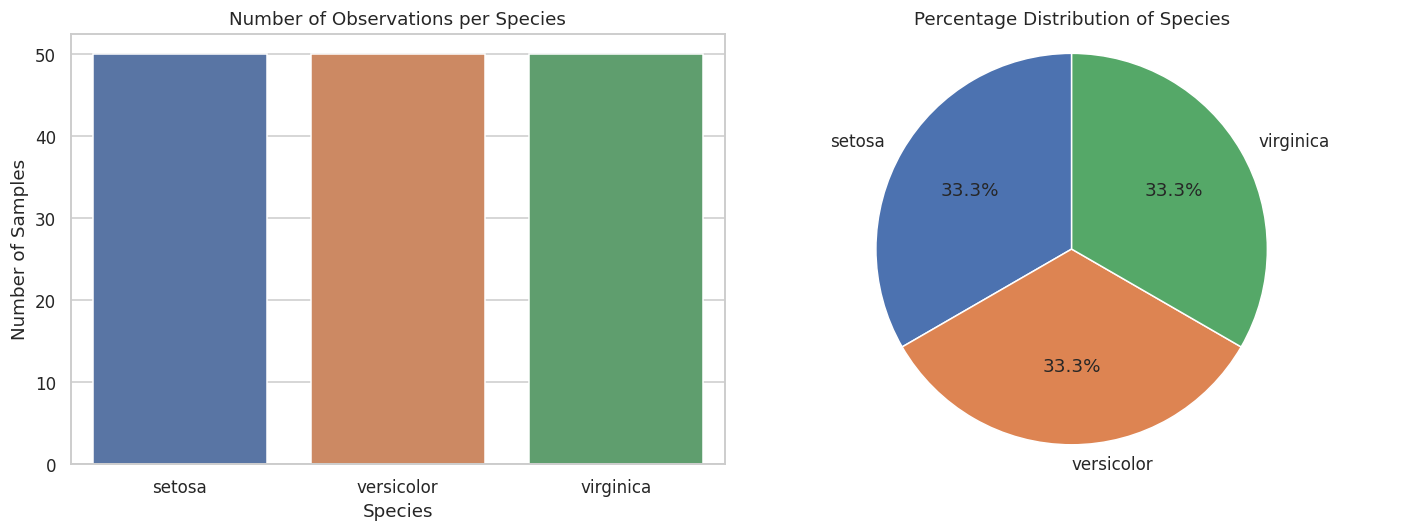

In [6]:

# ============================================================
# 4.3 TARGET CLASS DISTRIBUTION
# ============================================================

class_counts = df["species"].value_counts().reindex(target_names)

class_percentages = (
    df["species"].value_counts(normalize=True).reindex(target_names) * 100
)

class_distribution = pd.DataFrame({
    "Sample Count": class_counts,
    "Percentage (%)": class_percentages
})

print("Species Distribution")
display(class_distribution.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=df,
    x="species",
    order=target_names,
    hue="species",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Number of Observations per Species")
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Number of Samples")

axes[1].pie(
    class_counts,
    labels=target_names,
    autopct="%1.1f%%",
    startangle=90
)

axes[1].set_title("Percentage Distribution of Species")
axes[1].axis("equal")

plt.tight_layout()
plt.show()


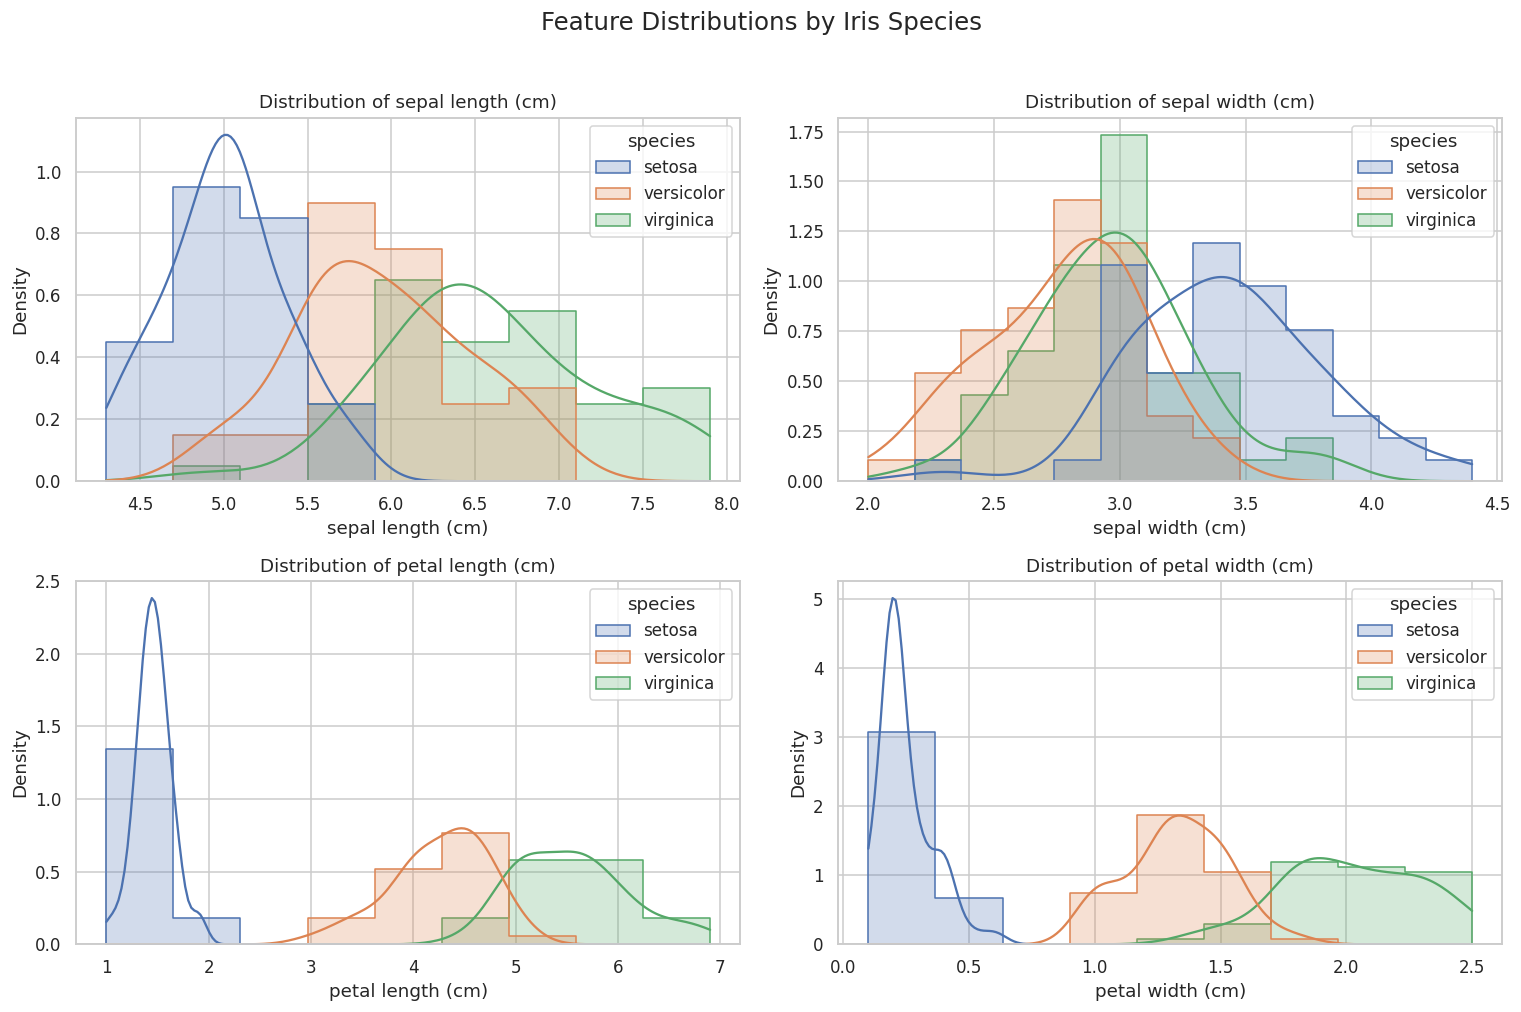

In [7]:

# ============================================================
# 4.4 FEATURE DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, feature in zip(axes, X.columns):
    sns.histplot(
        data=df,
        x=feature,
        hue="species",
        hue_order=target_names,
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_ylabel("Density")

plt.suptitle(
    "Feature Distributions by Iris Species",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


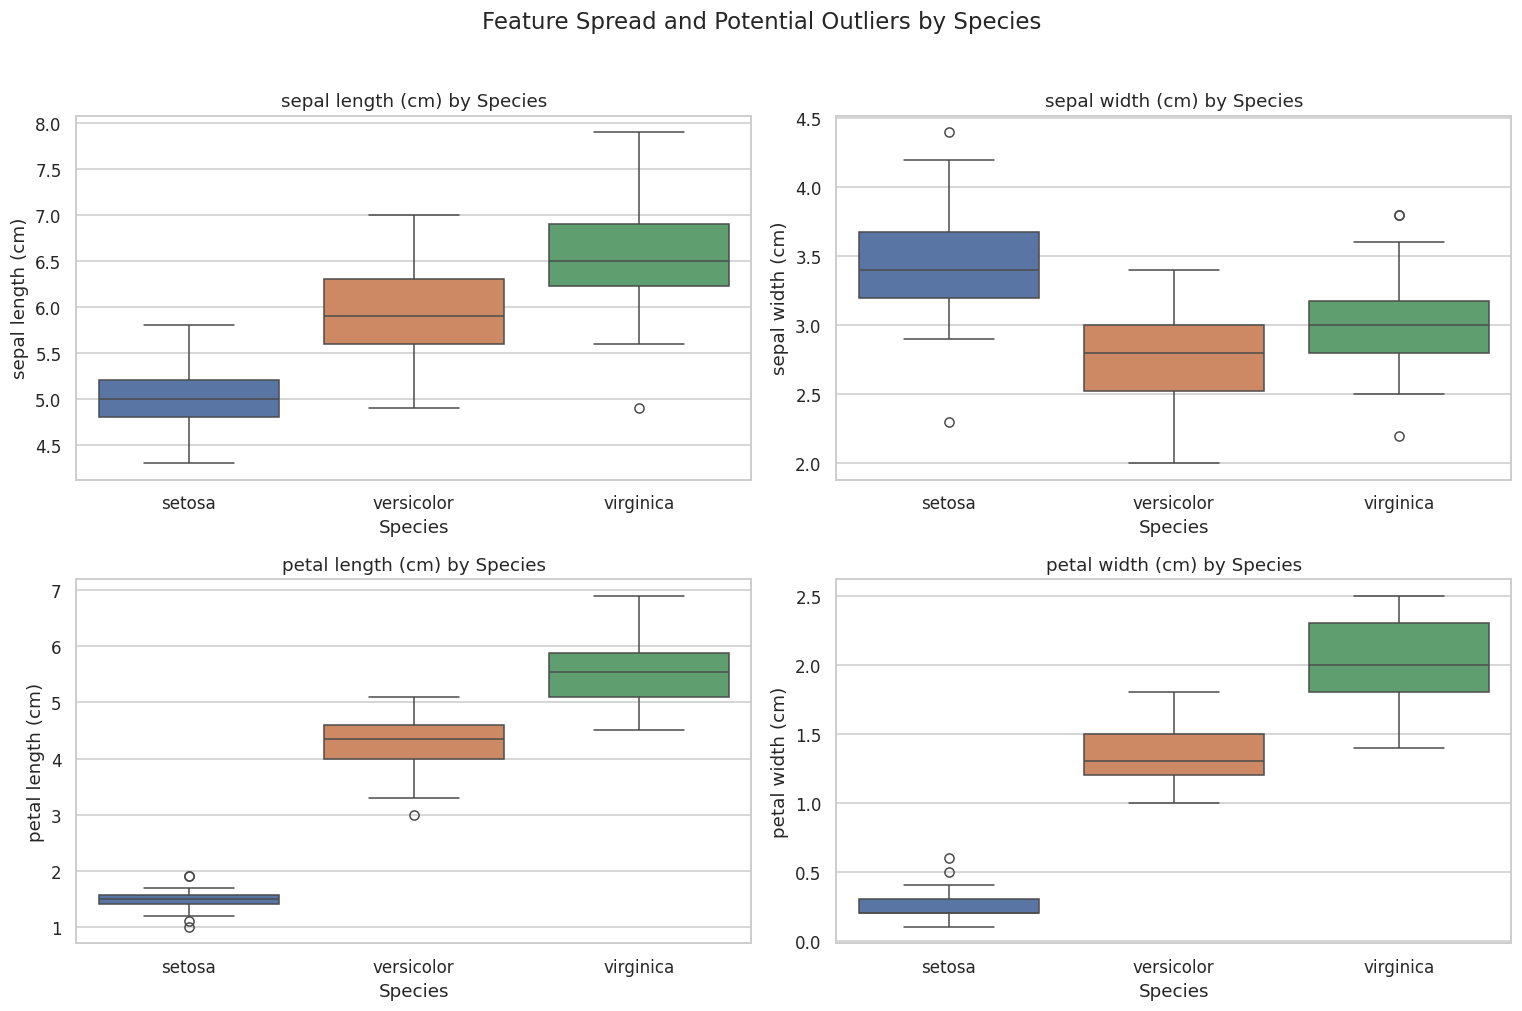

IQR-based potential outlier assessment


,Species,Feature,Lower Bound,Upper Bound,Potential Outliers
0,setosa,sepal length (cm),4.200,5.800,0
1,setosa,sepal width (cm),2.488,4.388,2
2,setosa,petal length (cm),1.137,1.838,4
3,setosa,petal width (cm),0.050,0.450,2
4,versicolor,sepal length (cm),4.550,7.350,0
5,versicolor,sepal width (cm),1.812,3.713,0
6,versicolor,petal length (cm),3.100,5.500,1
7,versicolor,petal width (cm),0.750,1.950,0
8,virginica,sepal length (cm),5.212,7.913,1
9,virginica,sepal width (cm),2.237,3.738,3


In [8]:

# ============================================================
# 4.5 BOX PLOT ANALYSIS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, feature in zip(axes, X.columns):
    sns.boxplot(
        data=df,
        x="species",
        y=feature,
        order=target_names,
        hue="species",
        legend=False,
        ax=ax
    )

    ax.set_title(f"{feature} by Species")
    ax.set_xlabel("Species")
    ax.set_ylabel(feature)

plt.suptitle(
    "Feature Spread and Potential Outliers by Species",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

# IQR-based flagging, calculated separately for each species
outlier_results = []

for species in target_names:
    species_df = df[df["species"] == species]

    for feature in X.columns:
        q1 = species_df[feature].quantile(0.25)
        q3 = species_df[feature].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        count = (
            (species_df[feature] < lower_bound) |
            (species_df[feature] > upper_bound)
        ).sum()

        outlier_results.append({
            "Species": species,
            "Feature": feature,
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound,
            "Potential Outliers": count
        })

outlier_summary = pd.DataFrame(outlier_results)

print("IQR-based potential outlier assessment")
display(outlier_summary.round(3))


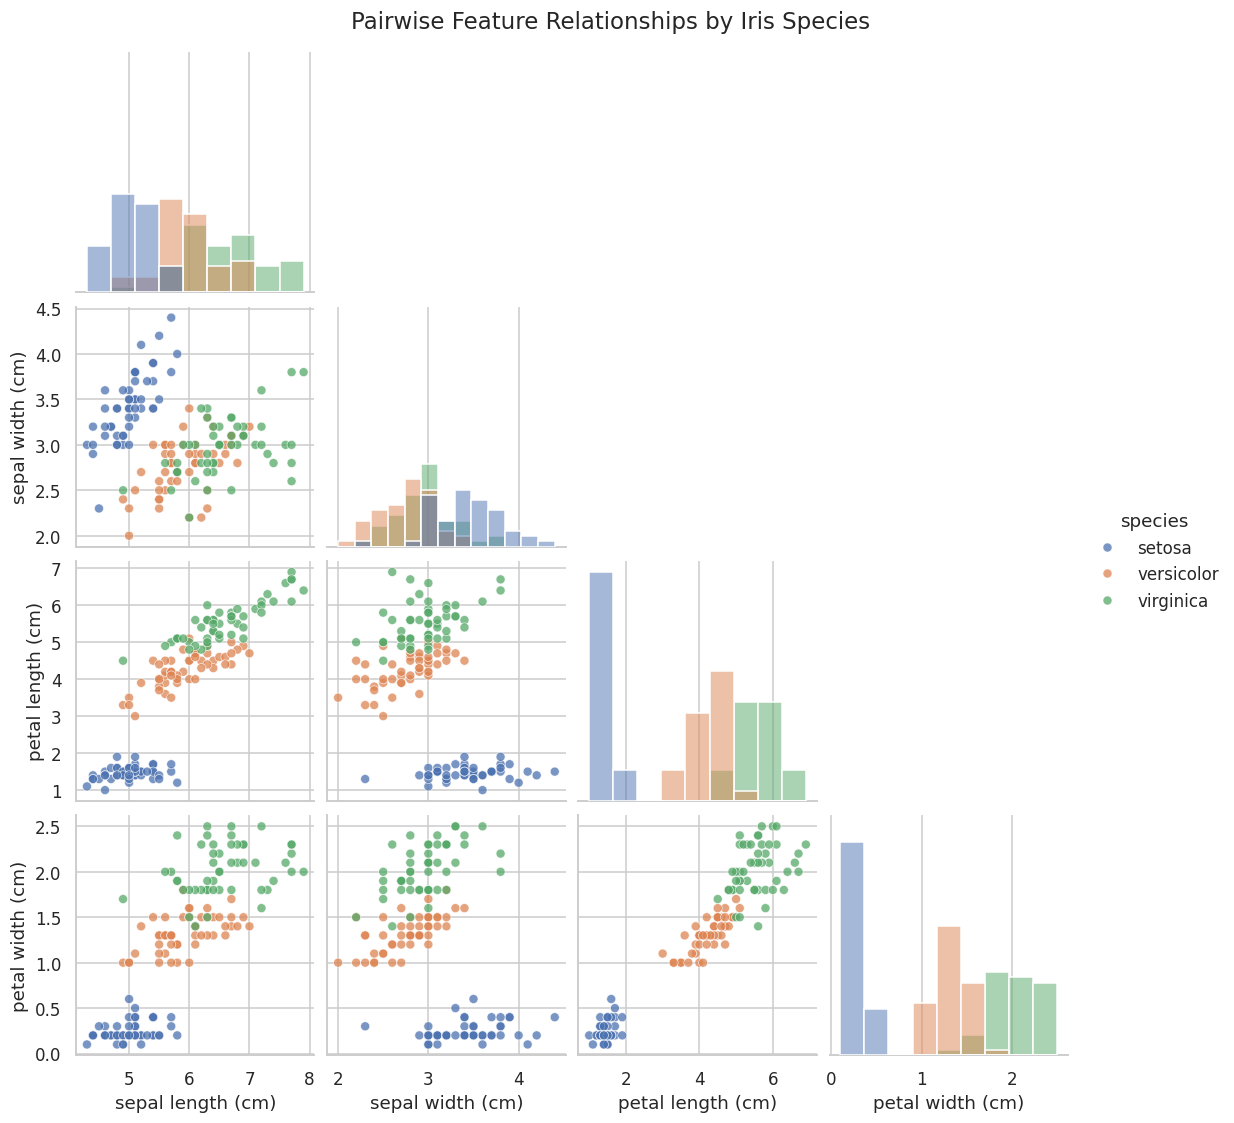

In [11]:

# ============================================================
# 4.6 PAIRWISE FEATURE RELATIONSHIPS
# ============================================================

pair_plot = sns.pairplot(
    df,
    vars=X.columns.tolist(),
    hue="species",
    hue_order=target_names,
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.75, "s": 35}
)

pair_plot.figure.suptitle(
    "Pairwise Feature Relationships by Iris Species",
    y=1.02,
    fontsize=15
)

plt.show()


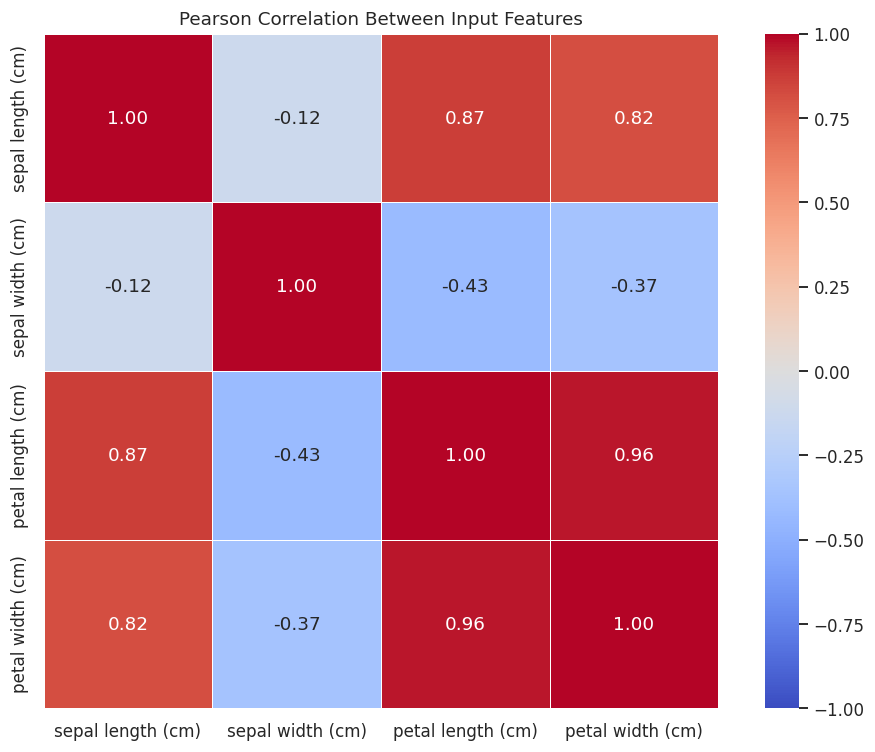

Correlation with petal length:


,Pearson Correlation
petal length (cm),1.000
petal width (cm),0.963
sepal length (cm),0.872
sepal width (cm),-0.428


In [10]:

# ============================================================
# 4.7 FEATURE CORRELATION ANALYSIS
# ============================================================

correlation_matrix = X.corr(method="pearson")

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Pearson Correlation Between Input Features")
plt.tight_layout()
plt.show()

print("Correlation with petal length:")
display(
    correlation_matrix["petal length (cm)"]
    .sort_values(ascending=False)
    .to_frame("Pearson Correlation")
)


In [12]:

# ============================================================
# 4.8 DUPLICATE OBSERVATION INVESTIGATION
# ============================================================

duplicate_mask = df.duplicated(keep=False)

print("Rows participating in exact duplicates:")
display(
    df.loc[duplicate_mask]
    .sort_values(by=X.columns.tolist())
)

print("\nNumber of duplicated rows after keeping the first occurrence:")
print(df.duplicated().sum())

print(
    "\nDecision: retain the original observations unless there is "
    "evidence that a duplicate is a data error."
)


Rows participating in exact duplicates:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica



Number of duplicated rows after keeping the first occurrence:
1

Decision: retain the original observations unless there is evidence that a duplicate is a data error.



## 5. EDA Findings and Feature Selection Strategy

### Key Findings

1. The dataset contains 150 observations and four numerical input features.
2. All features and target labels are complete, with no missing values.
3. The target classes are balanced, with 50 observations per species.
4. Petal length and petal width show strong differences between species.
5. Sepal measurements provide additional information but may show more overlap.
6. One exact duplicate observation exists and will be retained because there is no evidence that it is an erroneous record.
7. Potential outliers will be investigated rather than automatically removed.

### Feature Selection Decision

We will initially retain all four input features:
- Sepal length (cm)
- Sepal width (cm)
- Petal length (cm)
- Petal width (cm)

Petal measurements appear especially discriminative based on the descriptive statistics. However, we will evaluate the full feature set first and avoid selecting features solely from visual inspection.

### Preprocessing Strategy

- Missing values: no imputation is required for the current dataset.
- Duplicate observations: preserve the original dataset.
- Feature scaling: use StandardScaler for Logistic Regression and K-Nearest Neighbours.
- Tree-based models: scaling is generally unnecessary.
- Data splitting: use a stratified 80/20 train/test split.
- Validation: compare models using stratified cross-validation on the training set.
- Leakage prevention: fit all learned preprocessing steps within each model pipeline.


Train/test split

In [13]:

# ============================================================
# 6. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("\nTraining class distribution:")
display(y_train.value_counts().sort_index().rename(
    index=dict(enumerate(target_names))
).to_frame("Count"))

print("\nTest class distribution:")
display(y_test.value_counts().sort_index().rename(
    index=dict(enumerate(target_names))
).to_frame("Count"))

assert set(X_train.columns) == set(X_test.columns)
assert len(X_train) + len(X_test) == len(X)
assert X_train.index.intersection(X_test.index).empty

print("\nSplit validation passed.")


Training set shape: (120, 4)
Test set shape: (30, 4)

Training class distribution:


,Count
species,
setosa,40
versicolor,40
virginica,40



Test class distribution:


,Count
species,
setosa,10
versicolor,10
virginica,10



Split validation passed.


preprocessing

In [14]:

# ============================================================
# 7. DEFINE BASELINE AND CLASSIFICATION PIPELINES
# ============================================================

from sklearn.dummy import DummyClassifier

# Cross-validation configuration
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# All preprocessing is placed inside each pipeline.
# This ensures that scaling is learned from training folds only.

model_pipelines = {
    "Dummy Baseline": Pipeline([
        ("classifier", DummyClassifier(strategy="prior"))
    ]),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "K-Nearest Neighbours": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Decision Tree": Pipeline([
        ("classifier", DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

print("Pipelines defined:")
for name, pipeline in model_pipelines.items():
    print(f"\n{name}")
    print(pipeline)


Pipelines defined:

Dummy Baseline
Pipeline(steps=[('classifier', DummyClassifier())])

Logistic Regression
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

K-Nearest Neighbours
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier())])

Decision Tree
Pipeline(steps=[('classifier', DecisionTreeClassifier(random_state=42))])

Random Forest
Pipeline(steps=[('classifier',
                 RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                        random_state=42))])


Cross-validation model comparison

In [15]:

# ============================================================
# 8. CROSS-VALIDATION MODEL COMPARISON
# ============================================================

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

cv_results = []

for model_name, pipeline in model_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "Model": model_name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Accuracy Std": scores["test_accuracy"].std(),
        "CV Precision Macro": scores["test_precision_macro"].mean(),
        "CV Recall Macro": scores["test_recall_macro"].mean(),
        "CV F1 Macro": scores["test_f1_macro"].mean()
    })

cv_results_df = (
    pd.DataFrame(cv_results)
    .sort_values("CV F1 Macro", ascending=False)
    .reset_index(drop=True)
)

display(cv_results_df.round(4))


,Model,CV Accuracy Mean,CV Accuracy Std,CV Precision Macro,CV Recall Macro,CV F1 Macro
0,Logistic Regression,0.958,0.026,0.964,0.958,0.958
1,K-Nearest Neighbours,0.958,0.026,0.964,0.958,0.958
2,Decision Tree,0.950,0.017,0.957,0.950,0.950
3,Random Forest,0.950,0.031,0.959,0.950,0.949
4,Dummy Baseline,0.333,0.000,0.111,0.333,0.167


Hyperparameter tuning


## 9. Hyperparameter Tuning and Model Selection

We will tune Logistic Regression, K-Nearest Neighbours, Decision Tree, and Random Forest using GridSearchCV with five-fold stratified cross-validation.

Macro F1-score is the primary selection metric because it gives equal importance to all three species. Accuracy, precision, and recall will also be recorded.

The test set will not be used for hyperparameter tuning or candidate selection.


In [16]:

# ============================================================
# 9. HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import GridSearchCV

# Candidate models and their search spaces
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100]
    },

    "K-Nearest Neighbours": {
        "classifier__n_neighbors": [3, 5, 7, 9, 11],
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2]
    },

    "Decision Tree": {
        "classifier__max_depth": [None, 2, 3, 4, 5],
        "classifier__min_samples_leaf": [1, 2, 3],
        "classifier__criterion": ["gini", "entropy"]
    },

    "Random Forest": {
        "classifier__n_estimators": [200, 300],
        "classifier__max_depth": [None, 3, 5],
        "classifier__min_samples_leaf": [1, 2],
        "classifier__max_features": ["sqrt", None]
    }
}

search_results = []
search_objects = {}

for model_name, param_grid in param_grids.items():

    print(f"\nTuning: {model_name}")

    search = GridSearchCV(
        estimator=model_pipelines[model_name],
        param_grid=param_grid,
        scoring={
            "accuracy": "accuracy",
            "precision_macro": "precision_macro",
            "recall_macro": "recall_macro",
            "f1_macro": "f1_macro"
        },
        refit="f1_macro",
        cv=cv,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    search_objects[model_name] = search

    best_index = search.best_index_

    search_results.append({
        "Model": model_name,
        "Best CV Accuracy": search.cv_results_[
            "mean_test_accuracy"
        ][best_index],
        "Best CV Precision Macro": search.cv_results_[
            "mean_test_precision_macro"
        ][best_index],
        "Best CV Recall Macro": search.cv_results_[
            "mean_test_recall_macro"
        ][best_index],
        "Best CV F1 Macro": search.best_score_,
        "CV F1 Std": search.cv_results_[
            "std_test_f1_macro"
        ][best_index],
        "Best Parameters": search.best_params_
    })

    print("Best parameters:", search.best_params_)
    print(f"Best CV macro F1: {search.best_score_:.4f}")

tuning_results = (
    pd.DataFrame(search_results)
    .sort_values(
        ["Best CV F1 Macro", "Best CV Accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTuned Model Comparison")
display(tuning_results.round(4))



Tuning: Logistic Regression
Best parameters: {'classifier__C': 10}
Best CV macro F1: 0.9663

Tuning: K-Nearest Neighbours
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'uniform'}
Best CV macro F1: 0.9665

Tuning: Decision Tree
Best parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 3}
Best CV macro F1: 0.9663

Tuning: Random Forest
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}
Best CV macro F1: 0.9663

Tuned Model Comparison


,Model,Best CV Accuracy,Best CV Precision Macro,Best CV Recall Macro,Best CV F1 Macro,CV F1 Std,Best Parameters
0,K-Nearest Neighbours,0.967,0.970,0.967,0.967,0.017,"{'classifier__n_neighbors': 3, 'classifier__p'..."
1,Logistic Regression,0.967,0.972,0.967,0.966,0.032,{'classifier__C': 10}
2,Decision Tree,0.967,0.972,0.967,0.966,0.032,"{'classifier__criterion': 'gini', 'classifier_..."
3,Random Forest,0.967,0.972,0.967,0.966,0.032,"{'classifier__max_depth': 3, 'classifier__max_..."


In [17]:

# ============================================================
# 10. SELECT THE BEST CROSS-VALIDATED MODEL
# ============================================================

best_model_name = tuning_results.iloc[0]["Model"]
best_search = search_objects[best_model_name]

# GridSearchCV has already refitted this pipeline on all X_train.
final_pipeline = best_search.best_estimator_

print("Selected model:", best_model_name)
print("Best parameters:", best_search.best_params_)
print(f"Cross-validated macro F1: {best_search.best_score_:.4f}")

print("\nSelected fitted pipeline:")
print(final_pipeline)


Selected model: K-Nearest Neighbours
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'uniform'}
Cross-validated macro F1: 0.9665

Selected fitted pipeline:
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier(n_neighbors=3))])


evaluation

Classification metrics and confusion matrix

FINAL MODEL EVALUATION
Selected model: K-Nearest Neighbours
Test accuracy:       0.9333
Test macro precision: 0.9444
Test macro recall:   0.9333
Test macro F1-score: 0.9327

Classification Report:

              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.8333    1.0000    0.9091        10
   virginica     1.0000    0.8000    0.8889        10

    accuracy                         0.9333        30
   macro avg     0.9444    0.9333    0.9327        30
weighted avg     0.9444    0.9333    0.9327        30



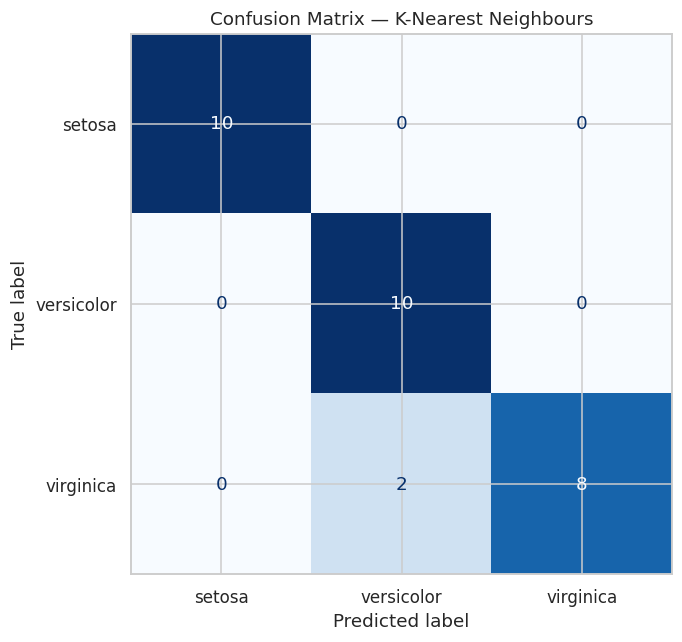

In [18]:

# ============================================================
# 11. FINAL TEST SET EVALUATION
# ============================================================

# Predict using the selected, fitted pipeline
y_pred = final_pipeline.predict(X_test)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
test_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
test_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("=" * 60)
print("FINAL MODEL EVALUATION")
print("=" * 60)

print("Selected model:", best_model_name)
print(f"Test accuracy:       {test_accuracy:.4f}")
print(f"Test macro precision:{test_precision: .4f}")
print(f"Test macro recall:   {test_recall:.4f}")
print(f"Test macro F1-score: {test_f1:.4f}")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


In [20]:

# ============================================================
# 12. SAVE THE FINAL MODEL ARTIFACT
# ============================================================

from pathlib import Path
from importlib.metadata import version
import joblib

MODEL_DIR = Path("/content/iris_model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "iris_classification_pipeline.joblib"

model_artifact = {
    "pipeline": final_pipeline,
    "model_name": best_model_name,
    "best_params": best_search.best_params_,
    "feature_names": X.columns.tolist(),
    "target_names": target_names.tolist(),
    "target_mapping": {
        int(index): str(name)
        for index, name in enumerate(target_names)
    },
    "cv_macro_f1": float(best_search.best_score_),
    "test_metrics": {
        "accuracy": float(test_accuracy),
        "precision_macro": float(test_precision),
        "recall_macro": float(test_recall),
        "f1_macro": float(test_f1)
    },
    "sklearn_version": version("scikit-learn"),
    "random_state": RANDOM_STATE
}

joblib.dump(model_artifact, MODEL_PATH)

print("Model artifact saved successfully.")
print("Location:", MODEL_PATH)
print(f"Artifact size: {MODEL_PATH.stat().st_size:,} bytes")
print("Selected model:", model_artifact["model_name"])
print("Scikit-learn version:", model_artifact["sklearn_version"])


Model artifact saved successfully.
Location: /content/iris_model/iris_classification_pipeline.joblib
Artifact size: 12,753 bytes
Selected model: K-Nearest Neighbours
Scikit-learn version: 1.6.1


In [21]:

# ============================================================
# 13. RELOAD AND VERIFY THE SAVED PIPELINE
# ============================================================

loaded_artifact = joblib.load(MODEL_PATH)

loaded_pipeline = loaded_artifact["pipeline"]

# Use one held-out observation for a smoke test
sample_flower = X_test.iloc[[0]].copy()

original_prediction = final_pipeline.predict(sample_flower)
reloaded_prediction = loaded_pipeline.predict(sample_flower)

assert np.array_equal(
    original_prediction,
    reloaded_prediction
), "Reloaded pipeline predictions do not match!"

predicted_class_id = int(reloaded_prediction[0])
predicted_species = loaded_artifact["target_mapping"][
    predicted_class_id
]

print("Reload verification passed.")
print("\nInput measurements:")
display(sample_flower)

print("Predicted species:", predicted_species)
print("Prediction class ID:", predicted_class_id)
print("Model:", loaded_artifact["model_name"])

# Optional: display class probabilities
if hasattr(loaded_pipeline, "predict_proba"):
    probabilities = loaded_pipeline.predict_proba(sample_flower)[0]

    probability_df = pd.DataFrame({
        "Species": [
            loaded_artifact["target_mapping"][int(class_id)]
            for class_id in loaded_pipeline.classes_
        ],
        "Predicted Probability": probabilities
    }).sort_values(
        "Predicted Probability",
        ascending=False
    )

    display(probability_df.reset_index(drop=True))


Reload verification passed.

Input measurements:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
38,4.4,3.0,1.3,0.2


Predicted species: setosa
Prediction class ID: 0
Model: K-Nearest Neighbours


,Species,Predicted Probability
0,setosa,1.0
1,versicolor,0.0
2,virginica,0.0
